# Missed appointments, scored at the moment of booking

Sammy Niyonkuru. Machine learning summative. This is the notebook I actually run, on Google Colab.

The desk question: when a clerk confirms a slot, which bookings are worth a reminder, and which ones should I leave alone? Accuracy is the wrong headline. About four bookings in five are attended, so a model that always says "they will come" is right most of the time and useless at the desk.

I am not trying to cancel slots. A false alarm is a phone call. A miss is an empty chair somebody else could have used. Those are not the same mistake. The threshold later on is there for that reason.

The data are public appointments from Vitória, Brazil (Hoppen / Aquarela, Kaggle, CC BY-NC-SA 4.0), 29 April to 8 June 2016. They are not from an African clinic. My mission is about outpatient queues in African hospitals, and I do not want a reader to think I trained on one and deployed to the other. Dantas and colleagues put the no-show rate in several African series near 43%. This file sits near 20%. The weights do not transfer. The booking-time problem does.

`TRAIN` is True. The long cell below fits every model and writes `experiments/results.csv`, the figures, and `models/`. I kept the fitting code in `src/noshow/` so I would not paste the same training block into ten cells and then change one of them and forget the others.


## Colab setup

Colab, if you open this file from GitHub, downloads the `.ipynb` and nothing else. The cleaning and the models live next to it, in `src/`. The first code cell finds that folder, or clones the repo if you pasted the URL.

I turn the GPU off on purpose. The first time I left it on, the network AUCs wandered in the third decimal and the report and the notebook stopped agreeing. The forest does not use the GPU anyway. Seed is 42.

If Colab says the runtime needs a restart after the install, restart it, then run again from the top. Don't skip the install the second time or you'll be on Colab's old TensorFlow and mine at the same time.

Packages, same pins as `requirements.txt`: numpy 2.5.4, pandas 3.0.6, scikit-learn 1.9.1, scipy 1.18.1, matplotlib 3.11.2, seaborn 0.13.2, joblib 1.6.0, tensorflow 2.21.0, keras 3.15.1, tensorboard 2.21.0, wandb 0.31.0.


In [1]:
import os
import sys
import subprocess
from pathlib import Path

# Paste the public GitHub URL once the repo exists. Colab needs it.
# Leave it blank when src/ is already on the machine (this is how I run it locally too).
REPO_URL = ""

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["WANDB_MODE"] = "offline"
os.environ["WANDB_SILENT"] = "true"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PACKAGES = [
    "numpy==2.5.4",
    "pandas==3.0.6",
    "scikit-learn==1.9.1",
    "scipy==1.18.1",
    "matplotlib==3.11.2",
    "seaborn==0.13.2",
    "joblib==1.6.0",
    "tensorflow==2.21.0",
    "keras==3.15.1",
    "tensorboard==2.21.0",
    "wandb==0.31.0",
]

if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])
    print("installed", ", ".join(PACKAGES))
else:
    print("not Colab, so I am not pip-installing over the venv")
    print("packages the Colab cell installs:", ", ".join(PACKAGES))


def find_root():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents]
    candidates += [Path("/content"), Path("/content/noshow-project")]
    for p in candidates:
        if (p / "src" / "noshow" / "pipeline.py").exists():
            return p
    return None


ROOT = find_root()
if ROOT is None and IN_COLAB:
    if not REPO_URL.strip():
        raise SystemExit(
            "Colab only opened the notebook. Put the GitHub URL in REPO_URL at the top of this cell and run it again."
        )
    dest = Path("/content/noshow-project")
    if not (dest / "src").exists():
        subprocess.check_call(["git", "clone", "--depth", "1", REPO_URL.strip(), str(dest)])
    ROOT = dest

if ROOT is None:
    raise SystemExit("Could not find src/noshow. Run this notebook from the repo root, or set REPO_URL on Colab.")

os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
print("Colab" if IN_COLAB else "local", "| root", ROOT)


not Colab, so I am not pip-installing over the venv
packages the Colab cell installs: numpy==2.5.4, pandas==3.0.6, scikit-learn==1.9.1, scipy==1.18.1, matplotlib==3.11.2, seaborn==0.13.2, joblib==1.6.0, tensorflow==2.21.0, keras==3.15.1, tensorboard==2.21.0, wandb==0.31.0
local | root /workspace


## Load and clean

`PatientId` has to be read as text. As a float, distinct people collapse into the same id and the patient split becomes a fiction.

Lead time is a calendar-date difference. The appointment clock in this file is midnight, so subtracting the raw timestamps turns an afternoon same-day booking into a negative wait. I burned an evening on that before I noticed every `AppointmentDay` was `00:00:00`. Ages below 0 or above 100, and the five rows with a negative date gap, come out. The flags are already 0/1, so there is nothing to impute.

The csv is downloaded into `data/` if it is missing. It is not committed. Licence is CC BY-NC-SA 4.0.


In [2]:
import json
import numpy as np
import pandas as pd

from noshow.config import EXP_DIR, FIG_DIR, MODEL_DIR, SEED
from noshow.data import clean, load_raw
from noshow.features import add_booking_time_history, apply_neighbourhood
from noshow.models import (
    build_mlp_functional,
    build_mlp_sequential,
    compile_binary,
    make_tfdata,
    make_tfdata_embed,
    set_seeds,
)
from noshow.plots import plot_eda
from noshow.splitting import split_by_patient, split_summary

set_seeds(SEED)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)
print("seed", SEED)

raw = load_raw()
df, report = clean(raw)
print("raw rows", report["rows_raw"])
print(
    "dropped age / negative lead / gender / duplicate:",
    report["dropped_age"],
    report["dropped_negative_lead"],
    report["dropped_gender"],
    report["dropped_duplicate_appointment"],
)
print("rows after", len(df), "patients", report["patients"])
print("no-show rate", round(report["noshow_rate"], 4), "same-day share", round(report["same_day_rate"], 4))
print("appointment dates", report["date_min"], "to", report["date_max"], "| neighbourhoods", report["neighbourhoods"])
df[["patient_id", "scheduled_day", "appointment_day", "lead_days", "age", "noshow"]].head(3)


I0000 00:00:1792410363.648353   20374 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792410363.648884   20374 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792410364.642093   20374 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792410364.642409   20374 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


seed 42


raw rows 110527
dropped age / negative lead / gender / duplicate: 8 5 0 0
rows after 110514 patients 62294
no-show rate 0.2019 same-day share 0.3489
appointment dates 2016-04-29 to 2016-06-08 | neighbourhoods 81


,patient_id,scheduled_day,appointment_day,lead_days,age,noshow
0,29872499824296,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,0,62,0
1,558997776694438,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,0,56,0
2,4262962299951,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,0,62,0


## Same-day is most of the pattern

If the visit is today, almost nobody misses it. Once the gap is a week or more the rate sits around 30% and then flattens. A reminder policy that ignores lead time is arguing with the largest thing in the file.

The printout below is a same-day afternoon booking. The clock on the booking is late, the appointment stamp is midnight, and the lead I keep is still 0.


In [3]:
afternoon = df[(df["lead_days"] == 0) & (df["scheduled_hour"] >= 15)].head(2)
print(afternoon[["scheduled_day", "appointment_day", "scheduled_hour", "lead_days", "noshow"]].to_string(index=False))

lead_bins = pd.cut(
    df["lead_days"],
    bins=[-0.1, 0, 2, 7, 14, 30, 10_000],
    labels=["0 (same day)", "1-2", "3-7", "8-14", "15-30", "31+"],
)
by_lead = df.groupby(lead_bins, observed=True)["noshow"].agg(rate="mean", n="size")
print(by_lead.round(4))
print("same-day share of rows", round(float((df["lead_days"] == 0).mean()), 4))


            scheduled_day           appointment_day  scheduled_hour  lead_days  noshow
2016-04-29 18:38:08+00:00 2016-04-29 00:00:00+00:00              18          0       0
2016-04-29 16:08:27+00:00 2016-04-29 00:00:00+00:00              16          0       0
                rate      n
lead_days                  
0 (same day)  0.0465  38560
1-2           0.2274  11937
3-7           0.2497  20245
8-14          0.3047  12025
15-30         0.3259  17370
31+           0.3300  10377
same-day share of rows 0.3489


## History the clerk could actually know

Sorting by appointment date and shifting the previous label looks tidy and it leaks. A patient can book June, then later book a May slot. Shift in appointment order and the June outcome is treated as already known when the May visit was booked. It was not.

Rule I use: a past visit counts only when its appointment date is strictly before the calendar day of *this* booking. Same-day visits do not count. The toy patient is the same one as `tests/test_history.py`. Appointment `c` is booked on 25 May. The 20 May visit has happened (attended). The 10 June visit has not, even though it was booked earlier and was missed. So `c` has one prior visit and zero prior no-shows.


In [4]:
toy = pd.DataFrame(
    [
        ("p", "a", "2016-05-01", "2016-06-10", 1),
        ("p", "b", "2016-05-05", "2016-05-20", 0),
        ("p", "c", "2016-05-25", "2016-06-02", 1),
        ("p", "d", "2016-06-05", "2016-06-20", 0),
    ],
    columns=["patient_id", "appointment_id", "sched", "appt", "noshow"],
)
toy["sched_date"] = pd.to_datetime(toy["sched"])
toy["appt_date"] = pd.to_datetime(toy["appt"])
toy_out = add_booking_time_history(toy).set_index("appointment_id")
print(toy_out[["prior_appointments", "prior_noshows", "prior_noshow_rate", "days_since_last"]])
assert toy_out.loc["c", "prior_appointments"] == 1
assert int(toy_out.loc["c", "prior_noshows"]) == 0
assert toy_out.loc["d", "prior_appointments"] == 2
assert abs(float(toy_out.loc["d", "prior_noshow_rate"]) - 0.5) < 1e-9
print("toy patient matches the unit test")


                prior_appointments  prior_noshows  prior_noshow_rate  days_since_last
appointment_id                                                                       
b                                0              0                0.0              0.0
c                                1              0                0.0              5.0
a                                0              0                0.0              0.0
d                                2              1                0.5              3.0
toy patient matches the unit test


On the real file most rows still have an empty history. The extract is about six weeks, so a first visit inside the window has nothing behind it. I do not expect personal history to carry the model, whatever the papers on longer panels found.


In [5]:
df = add_booking_time_history(df)
print("share of rows with any prior visit", round(float(df["has_prior"].mean()), 4))
print("mean prior no-show rate | attended", round(float(df.loc[df["noshow"] == 0, "prior_noshow_rate"].mean()), 4))
print("mean prior no-show rate | missed   ", round(float(df.loc[df["noshow"] == 1, "prior_noshow_rate"].mean()), 4))


share of rows with any prior visit 0.2794
mean prior no-show rate | attended 0.0529
mean prior no-show rate | missed    0.0649


## SMS, before I refuse to use it as a feature

No same-day booking in this file received a text. Compare "got an SMS" with "did not" and you are mostly comparing long waits with same-day visits, so the text looks harmful. Restrict to lead time of at least three days and the gap flips. I still leave SMS out of the main models. Sending the text is a decision the desk makes, not a description of the patient at the moment I want a score. One ablation (E09) is enough. I would not call either comparison causal.


In [6]:
print("SMS share on same-day bookings", float(df.loc[df["lead_days"] == 0, "sms_received"].mean()))
print("no-show rate, SMS vs none, all rows")
print(df.groupby("sms_received")["noshow"].mean().round(4))
print("no-show rate, SMS vs none, lead >= 3 days")
print(df.loc[df["lead_days"] >= 3].groupby("sms_received")["noshow"].mean().round(4))
plot_eda(df, FIG_DIR)
print("wrote EDA figures to", FIG_DIR)


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


SMS share on same-day bookings 0.0
no-show rate, SMS vs none, all rows
sms_received
0    0.1670
1    0.2758
Name: noshow, dtype: float64
no-show rate, SMS vs none, lead >= 3 days
sms_received
0    0.3269
1    0.2758
Name: noshow, dtype: float64


wrote EDA figures to /workspace/figures


## Patient split

Appointments from the same person are not independent. A random row split puts the patient on both sides, and a history feature then gets a free look at their habit.

My first splitter was worse than a random one. I filled the test set by walking strata, and the patients who sometimes miss got used up. Train was left full of people who always attend. On a smoke sample the no-show rate was about 14% in train and 30% in test. I threw those numbers away.

The split below works inside each stratum (never missed / mixed / missed at least half) so each side keeps the same mix. Validation is 15% of the non-test rows. Seed 42. The training cell uses this same function, so the counts should match what it prints.


In [7]:
train_idx, val_idx, test_idx = split_by_patient(df, test_size=0.20, val_size=0.15, seed=SEED)
summary = split_summary(df, train_idx, val_idx, test_idx)
for name in ("train", "val", "test"):
    row = summary[name]
    print(
        f"{row['split']:5} rows={row['rows']:6}  patients={row['patients']:6}  "
        f"no-show={row['noshow_rate']:.4f}  has_prior={row['has_prior_rate']:.3f}"
    )
assert summary["train"]["rows"] == 75140
assert summary["test"]["rows"] == 22105
overlap = set(df.iloc[train_idx]["patient_id"]) & set(df.iloc[test_idx]["patient_id"])
assert len(overlap) == 0
print("no shared patients between train and test")


train rows= 75140  patients= 42304  no-show=0.2016  has_prior=0.281
val   rows= 13269  patients=  7492  no-show=0.2030  has_prior=0.269
test  rows= 22105  patients= 12498  no-show=0.2021  has_prior=0.279


no shared patients between train and test


## What the two families look like, before the long fit

Traditional side, all in scikit-learn: a constant-prevalence baseline, logistic regression, a small C grid with class weights, random forests, histogram gradient boosting at two learning rates, and a linear SVM. The C grid was flat the last time I ran it. I am not going to pretend a flat grid taught me something about regularisation. The forest search did. A leaf of 2 memorised (training AUC up near 0.92, inner holdout no better). A leaf of 10 is the one I kept.

Deep side: Keras. E11 is Sequential, 64 then 32, dropout 0.2, Adam at 1e-3, class weights, fed with `tf.data`. E12 is deeper, with batch norm and more dropout. E13 is that same net at learning rate 1e-2. I expected it to blow up. It didn't, and it didn't win either. E14 drops the class weights. E15 is the Functional API: neighbourhood goes in as an embedding instead of a smoothed rate.

The summaries below are the shapes, built on a handful of rows so I can see the `tf.data` batch. I do not save these weights. The next cell is the real training.


In [8]:
train_df = df.iloc[train_idx]
rng = np.random.RandomState(SEED)
tiny = train_df.iloc[rng.choice(len(train_df), size=2048, replace=False)]
cols_smoke = ["age", "lead_days", "same_day", "prior_noshows", "female"]
X = tiny[cols_smoke].to_numpy(dtype=np.float32)
X = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-6)
y = tiny["noshow"].to_numpy(dtype=np.float32)
neigh = np.zeros(len(tiny), dtype=np.int32)

# Same widths as E11, but this object is only here so the summary is visible.
seq = build_mlp_sequential(n_features=22, widths=[64, 32], dropout=0.2, batch_norm=False)
compile_binary(seq, learning_rate=1e-3)
seq.summary()

fun = build_mlp_functional(n_features=20, n_neighbourhoods=81, embed_dim=8)
compile_binary(fun, learning_rate=1e-3)
fun.summary()

ds = make_tfdata(X, y, batch=256, shuffle=True, seed=SEED)
ds_emb = make_tfdata_embed(X, neigh, y, batch=256, shuffle=False, seed=SEED)
batch_x, batch_y = next(iter(ds_emb))
print("sequential tf.data element", next(iter(ds))[0].shape, next(iter(ds))[1].shape)
print("functional tf.data batch", {k: tuple(v.shape) for k, v in batch_x.items()}, tuple(batch_y.shape))
print("nothing from this cell is written to models/")


E0000 00:00:1792410366.828273   20374 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "mlp_sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_0 (Dense)                 │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_0 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_0 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ noshow_prob (Dense)             │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,585 (14.00 KB)

 Trainable params: 3,585 (14.00 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ neighbourhood       │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ neighbourhood_embe… │ (None, 8)         │        648 │ neighbourhood[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_flat (Flatten)  │ (None, 8)         │          0 │ neighbourhood_em… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ join (Concatenate)  │ (None, 28)        │          0 │ numeric[0][0],    │
│                     │                   │            │ emb_flat[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_0 (Dense)     │ (None, 64)        │      1,856 │ join[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ drop_0 (Dropout)    │ (None, 64)        │          0 │ dense_0[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ drop_0[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ noshow_prob (Dense) │ (None, 1)         │         33 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,617 (18.04 KB)

 Trainable params: 4,617 (18.04 KB)

 Non-trainable params: 0 (0.00 B)

sequential tf.data element (256, 5) (256,)
functional tf.data batch {'numeric': (256, 5), 'neighbourhood': (256,)} (256,)
nothing from this cell is written to models/


## Train

This is the cell I care about on Colab. `run(fast=False)` fits E00 through E15, including the inner C grid and the forest trials that never see the test patients. It writes:

- `experiments/results.csv` and one json per run under `experiments/runs/`
- learning curves, ROC, confusion matrices, into `figures/`
- `models/best_traditional.joblib` and `models/best_deep.keras` (and `.h5`)
- TensorBoard files under `experiments/tensorboard/`, and W&B offline under `experiments/wandb/`

Selection is the highest validation ROC-AUC inside each family. The test set is scored after that, not used to pick the winner. The F1 threshold is chosen on validation and frozen.

Leave `TRAIN = True` for the submission run. If you have already trained and you only want to reread the table, set it to False. `--fast` in the script is a smoke test on a patient sample. Do not quote it. I am not calling it here.

One rule I added after I got annoyed: if the networks are within 0.002 validation AUC, keep E11, the small one. A rerun once saved the high learning-rate net because the third decimal moved. That is TensorFlow, not a finding. The PDF quotes the forest at 0.736 and the small net at 0.731. This cell prints the run you just did. A thousandth either way is the same result.

On a CPU this has been a couple of minutes, not an hour. The forest is small. The nets stop early.


In [9]:
TRAIN = True

from noshow.pipeline import run

if TRAIN:
    results = run(fast=False)
else:
    results = pd.read_csv(EXP_DIR / "results.csv")
    print("TRAIN is False, loaded", EXP_DIR / "results.csv")

held = results.loc[results["stage"] == "heldout_test"].copy()
show = [
    "experiment_id",
    "algorithm",
    "features",
    "val_roc_auc",
    "roc_auc",
    "pr_auc",
    "precision_noshow",
    "recall_noshow",
    "f1_noshow",
    "brier",
    "threshold",
]
print("held-out runs", len(held), "| all logged rows", len(results))
held[show].round(3)


preparing data


split {'train': (75140, 0.202), 'val': (13269, 0.203), 'test': (22105, 0.202)}
fitting E01


fitting E02


searching logistic C


selected C 0.01 inner auc 0.7269


...

  curve E05 0.75 {'fraction': 0.75, 'train_rows': 56472, 'train_auc': 0.8611270521353566, 'val_auc': 0.7334911089320495}


  curve E05 1.0 {'fraction': 1.0, 'train_rows': 75140, 'train_auc': 0.855083368038634, 'val_auc': 0.7347953391518214}


permutation importance


experiment_id  roc_auc   pr_auc  f1_noshow  recall_noshow
          E00 0.500000 0.202081   0.336219       1.000000
          E01 0.716498 0.337113   0.440809       0.763152
          E02 0.724436 0.352903   0.441135       0.871950
          E03 0.724460 0.351955   0.441993       0.874636
          E04 0.733379 0.365516   0.450094       0.747034
          E05 0.736105 0.368529   0.450950       0.712111
          E06 0.735487 0.372625   0.450731       0.731139
          E07 0.734947 0.369769   0.451318       0.684352
          E08 0.724271 0.351800   0.442264       0.872845
          E09 0.726820 0.357359   0.448254       0.784419
          E10 0.726957 0.348706   0.444937       0.831690
          E11 0.731266 0.367922   0.447306       0.699799
          E12 0.731593 0.366160   0.449619       0.719722
          E13 0.731457 0.370047   0.448808       0.718827
          E14 0.729695 0.364072   0.448677       0.777927
          E15 0.732810 0.366368   0.448719       0.851131
held-out runs 

,experiment_id,algorithm,features,val_roc_auc,roc_auc,pr_auc,precision_noshow,recall_noshow,f1_noshow,brier,threshold
0,E00,majority_prevalence,none,0.500,0.500,0.202,0.202,1.000,0.336,0.161,0.202
1,E01,logreg,base_booking,0.715,0.716,0.337,0.310,0.763,0.441,0.146,0.233
2,E02,logreg,full_booking,0.719,0.724,0.353,0.295,0.872,0.441,0.145,0.191
7,E03,logreg_balanced,full_booking,0.719,0.724,0.352,0.296,0.875,0.442,0.216,0.484
8,E04,random_forest,full_booking,0.733,0.733,0.366,0.322,0.747,0.450,0.202,0.516
15,E05,random_forest_tuned,full_booking,0.735,0.736,0.369,0.330,0.712,0.451,0.194,0.507
16,E06,hist_gradient_boosting,full_booking,0.732,0.735,0.373,0.326,0.731,0.451,0.143,0.233
17,E07,hist_gradient_boosting,full_booking,0.729,0.735,0.370,0.337,0.684,0.451,0.143,0.251
18,E08,linear_svc,full_booking,0.719,0.724,0.352,0.296,0.873,0.442,NaN,-0.006
19,E09,logreg_balanced,full_booking_plus_sms,0.721,0.727,0.357,0.314,0.784,0.448,0.216,0.534


## Reading the table

E01 is booking fields without history. E02 adds history. The lift is small, which matches the empty-history rate above. E05 is the forest I save if it still wins on validation AUC. E06 (boosting) has been close, and better calibrated. If I had to quote a probability out loud I would start from E06, not from a class-weighted forest. E10 is a random appointment split, kept only to show how a leaky split flatters the score. E11 is the small network.

Lead time alone, computed in a later cell on the same test patients, sits near 0.693 AUC. The forest lands near 0.736. The gap is the result. The absolute AUC is not something I would brag about.

Class weights do not change logistic AUC. They change what 0.5 means. Last run, unweighted Brier was about 0.145 and weighted was about 0.216, which is worse than predicting the base rate (0.161). Reweighting fixed the cutoff and broke the probabilities.


## Figures from this run

Lead time dominates the EDA chart. The logistic learning curve barely moves once a tenth of the training patients are in, which is high bias: more rows will not invent a feature. The forest is the other shape, a gap between train and validation that the leaf size already tried to cut. I would not buy that gap down by growing the trees.

The ROC curves sit on top of each other. On the confusion matrix the threshold maximises F1 on validation, then it is frozen. It flags a large share of bookings and precision stays near one in three. That is a 20% base rate plus a weak ranking. A call list, not a reason to give the slot away.


**eda_lead_time.png.** No-show rate by lead time. Same-day is the low bar. After a week the rate flattens.

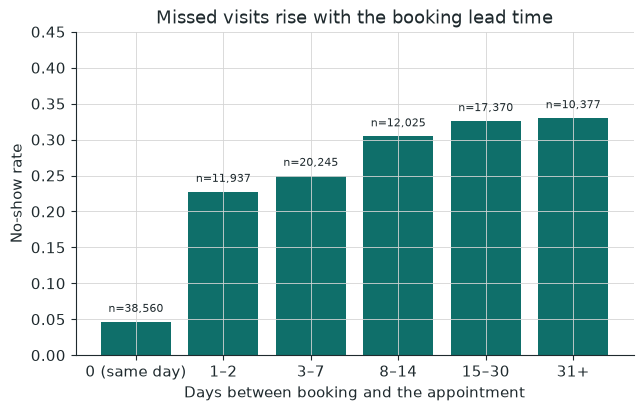

**eda_sms_by_lead.png.** The SMS comparison only makes sense inside a lead-time band.

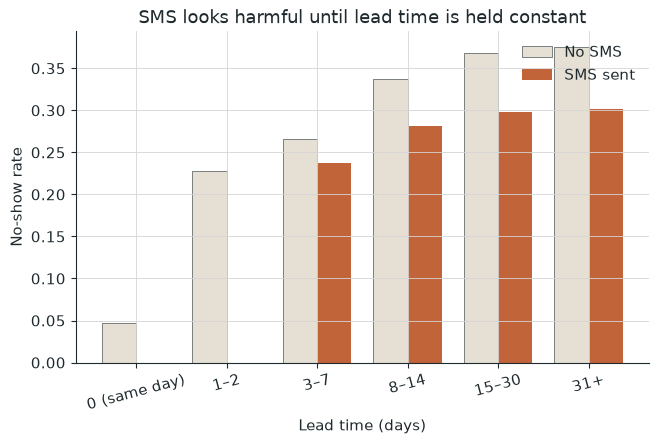

**learning_curve_logreg.png.** Logistic regression. Validation AUC hardly rises. More data does not fix this one.

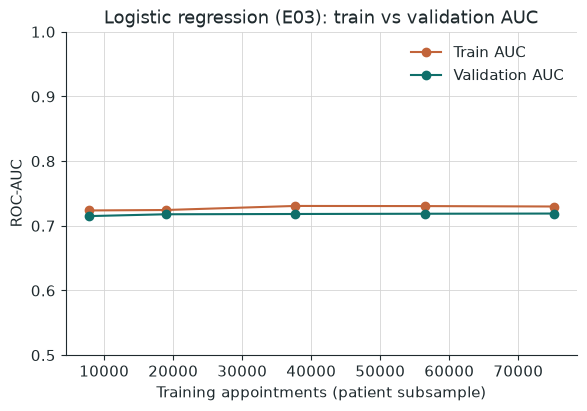

**learning_curve_tree.png.** Forest. The train/validation gap is still there after the leaf constraint.

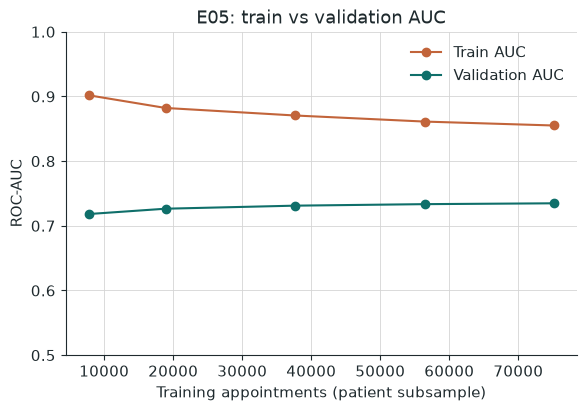

**dl_learning_curves.png.** The five networks. The higher learning rate does not diverge, and it does not win.

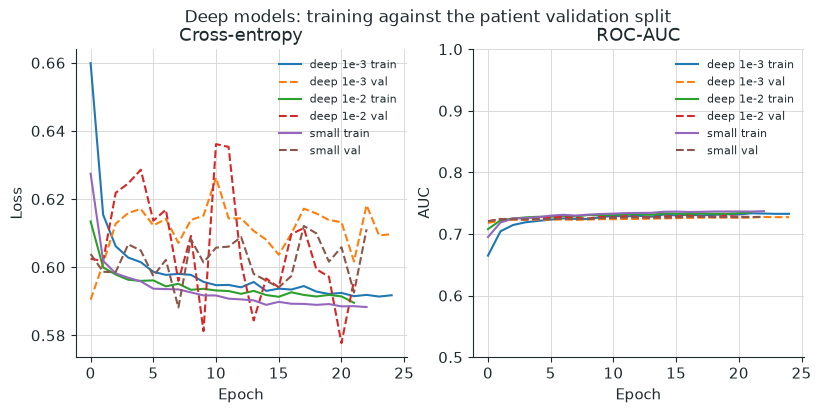

**roc_test.png.** Test ROC. Lead time already did most of the ranking.

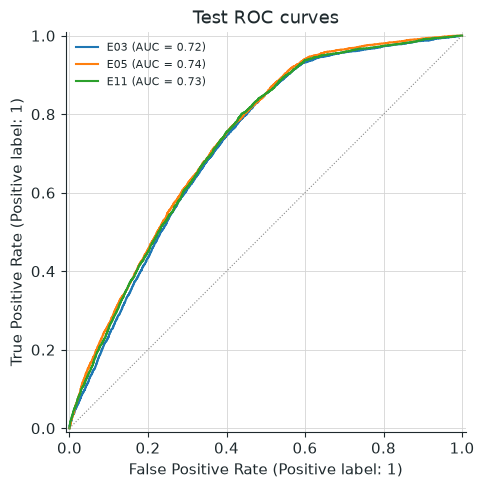

**pr_test.png.** Precision-recall on the test patients.

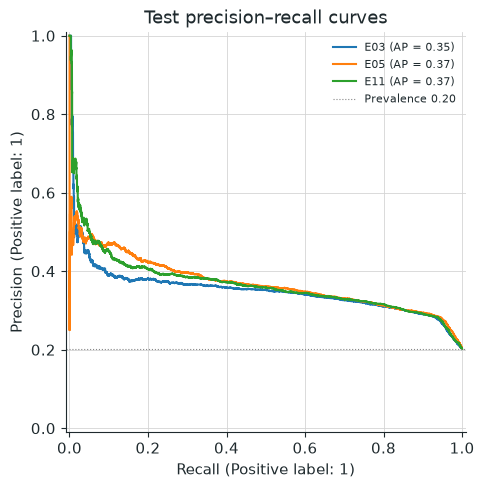

**cm_best_traditional.png.** Saved traditional model, validation F1 threshold. A lot of false alarms, on purpose.

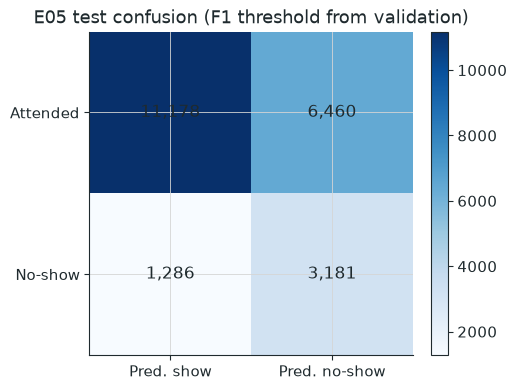

**cm_best_deep.png.** Saved network, its own frozen threshold.

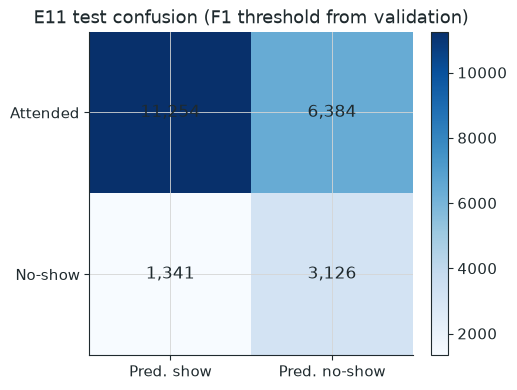

**slices_lead.png.** Saved forest on the test set, by lead time. Same-day is rarely flagged.

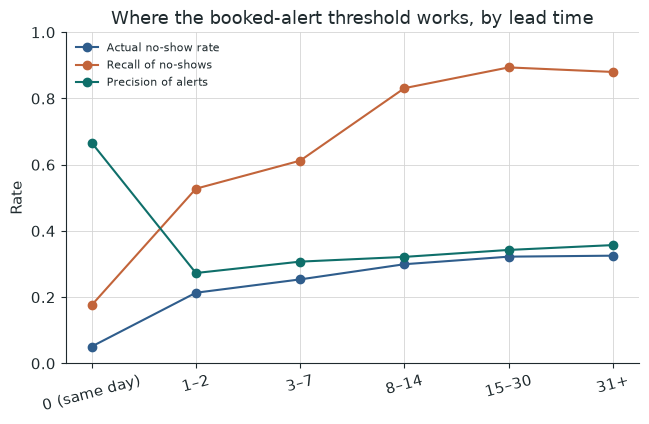

**permutation_importance.png.** Age moves AUC most when shuffled. That is not the same as age ranking well on its own.

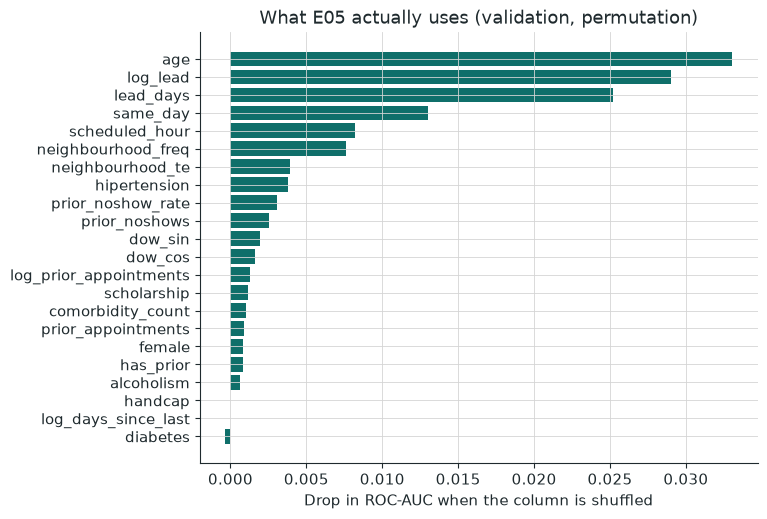

In [10]:
from IPython.display import Image, Markdown, display

figures = [
    ("eda_lead_time.png", "No-show rate by lead time. Same-day is the low bar. After a week the rate flattens."),
    ("eda_sms_by_lead.png", "The SMS comparison only makes sense inside a lead-time band."),
    ("learning_curve_logreg.png", "Logistic regression. Validation AUC hardly rises. More data does not fix this one."),
    ("learning_curve_tree.png", "Forest. The train/validation gap is still there after the leaf constraint."),
    ("dl_learning_curves.png", "The five networks. The higher learning rate does not diverge, and it does not win."),
    ("roc_test.png", "Test ROC. Lead time already did most of the ranking."),
    ("pr_test.png", "Precision-recall on the test patients."),
    ("cm_best_traditional.png", "Saved traditional model, validation F1 threshold. A lot of false alarms, on purpose."),
    ("cm_best_deep.png", "Saved network, its own frozen threshold."),
    ("slices_lead.png", "Saved forest on the test set, by lead time. Same-day is rarely flagged."),
    ("permutation_importance.png", "Age moves AUC most when shuffled. That is not the same as age ranking well on its own."),
]
for name, note in figures:
    path = FIG_DIR / name
    display(Markdown(f"**{name}.** {note}"))
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print("missing", path, "(training did not write it)")


## A lead-time rule, on the same test patients

I don't want "the model beats a simple rule" in the report unless the rule is computed here. Three dumb rankings: lead time, "not same-day", and age flipped (older patients attend more in this file). Then hard cuts on lead time: precision, recall, and how many bookings get flagged.

"Not today" already gets F1 around 0.43 while alerting about two thirds of the book. The forest's F1 is only a bit higher, at a lower alert rate. Real gain, small gain. I would not staff a call centre on the difference.


In [11]:
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

test = df.iloc[test_idx]
y = test["noshow"].to_numpy(dtype=int)
lead = test["lead_days"].to_numpy(dtype=float)

def hard_rule(mask):
    pred = mask.astype(int)
    return {
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "alert_rate": float(pred.mean()),
        "accuracy": float((pred == y).mean()),
    }

lead_rule = {
    "auc_lead_days": float(roc_auc_score(y, lead)),
    "auc_not_same_day": float(roc_auc_score(y, (lead > 0).astype(float))),
    "auc_negative_age": float(roc_auc_score(y, -test["age"].to_numpy(dtype=float))),
    "rules": {
        "lead>=1": hard_rule(lead >= 1),
        "lead>=3": hard_rule(lead >= 3),
        "lead>=7": hard_rule(lead >= 7),
        "lead>=14": hard_rule(lead >= 14),
    },
}
print("AUC lead time", round(lead_rule["auc_lead_days"], 4))
print("AUC not-same-day", round(lead_rule["auc_not_same_day"], 4))
print("AUC of minus age", round(lead_rule["auc_negative_age"], 4))
for name, stats in lead_rule["rules"].items():
    print(
        f"{name:8}  P={stats['precision']:.3f}  R={stats['recall']:.3f}  "
        f"F1={stats['f1']:.3f}  alert={stats['alert_rate']:.3f}"
    )
(EXP_DIR / "lead_rule.json").write_text(json.dumps(lead_rule, indent=2))


AUC lead time 0.6933
AUC not-same-day 0.6616
AUC of minus age 0.541
lead>=1   P=0.282  R=0.913  F1=0.430  alert=0.655
lead>=3   P=0.295  R=0.800  F1=0.431  alert=0.548
lead>=7   P=0.312  R=0.629  F1=0.417  alert=0.407
lead>=14  P=0.321  R=0.446  F1=0.374  alert=0.280


977

## Check the files the training cell just wrote

The forest is not scaled. Trees don't need it. The neighbourhood maps inside the joblib are the ones fit on the training patients. The network has a sidecar json with the scaler mean and scale. I scale every column the scaler saw, then keep the columns the net was trained on. Same trick as `_X` in the pipeline. If these AUCs drift from the csv, something about the split or the encoder changed and I should not trust the write-up.


In [12]:
import joblib

payload = joblib.load(MODEL_DIR / "best_traditional.joblib")
encoder = {
    "freq": payload["neighbourhood_freq"],
    "te": payload["neighbourhood_te"],
    "global_mean": payload["global_mean"],
    "index": {},
}
scored = apply_neighbourhood(test, encoder)
X_tree = scored[payload["columns"]].to_numpy(dtype=np.float64)
tree_scores = payload["model"].predict_proba(X_tree)[:, 1]
tree_auc = float(roc_auc_score(y, tree_scores))
thr = float(payload["threshold"])
flagged = tree_scores >= thr
print("saved model", payload["experiment_id"], "threshold", round(thr, 3))
print("test ROC-AUC", round(tree_auc, 4))
print(
    "precision", round(float(precision_score(y, flagged)), 3),
    "recall", round(float(recall_score(y, flagged)), 3),
    "alert", round(float(flagged.mean()), 3),
)
tp = int(((flagged == 1) & (y == 1)).sum())
fp = int(((flagged == 1) & (y == 0)).sum())
tn = int(((flagged == 0) & (y == 0)).sum())
fn = int(((flagged == 0) & (y == 1)).sum())
print("tp", tp, "fp", fp, "tn", tn, "fn", fn)


saved model E05 threshold 0.507
test ROC-AUC 0.7361
precision 0.33 recall 0.712 alert 0.436
tp 3181 fp 6460 tn 11178 fn 1286


In [13]:
from tensorflow import keras

side = json.loads((MODEL_DIR / "best_deep_preprocess.json").read_text())
mean = np.array(side["scaler_mean"], dtype=np.float64)
scale = np.array(side["scaler_scale"], dtype=np.float64)
raw_x = scored[side["scaler_columns"]].to_numpy(dtype=np.float64)
scaled = (raw_x - mean) / scale
frame = pd.DataFrame(scaled, columns=side["scaler_columns"])
X_net = frame[side["columns"]].to_numpy(dtype=np.float32)
# Arrays, not a shuffled dataset, so row i stays row i.
net = keras.models.load_model(MODEL_DIR / "best_deep.keras")
net_scores = net.predict(X_net, batch_size=1024, verbose=0).ravel()
net_auc = float(roc_auc_score(y, net_scores))
print("saved network", side["experiment_id"], side["kind"], "test ROC-AUC", round(net_auc, 4))
preview = scored[["lead_days", "age", "noshow"]].copy()
preview["forest"] = tree_scores
preview["network"] = net_scores
print(preview.head(8).round(3).to_string(index=False))


saved network E11 sequential test ROC-AUC 0.7313
 lead_days  age  noshow  forest  network
         2   13       0   0.603    0.579
        55    2       0   0.697    0.734
        67   47       0   0.615    0.587
         7    9       0   0.620    0.650
        17   39       1   0.685    0.702
         2   24       0   0.562    0.572
         0   76       0   0.047    0.095
        31   76       1   0.368    0.472


## Where the score is wrong in a way that matters

Age usually has the largest permutation drop, and on its own it still ranks poorly (the flipped-age AUC above is just over 0.5). The slice table is the part I would show a clinic manager. Young adults get recalled a lot. Patients 65 and older get recalled much less, and their base rate is lower, not zero. If the call list follows the score, older patients who will miss are the ones the desk does not phone. There is no fairness term in the loss. I am flagging the pattern, not claiming I fixed it.

Same-day visits are rarely flagged. Fine for a reminder list. A bad overbooking rule, because the people who actually miss a same-day slot are mostly left unmarked.


In [14]:
age_slices = pd.read_csv(EXP_DIR / "slices_age_test.csv")
lead_slices = pd.read_csv(EXP_DIR / "slices_lead_test.csv")
print("age slices, test patients, saved forest")
print(age_slices.round(3).to_string(index=False))
print()
print("lead slices, test patients, saved forest")
print(lead_slices.round(3).to_string(index=False))


age slices, test patients, saved forest
  bin    n  prevalence  precision  recall  fn   fp
 0-17 5447       0.217      0.334   0.813 221 1918
18-34 4838       0.237      0.359   0.894 122 1829
35-49 4488       0.209      0.319   0.762 224 1532
50-64 4576       0.167      0.286   0.463 411  886
  65+ 2756       0.157      0.296   0.287 308  295

lead slices, test patients, saved forest
         bin    n  prevalence  alert_rate  precision  recall  fn   fp
0 (same day) 7617       0.051       0.013      0.667   0.176 319   34
         1–2 2381       0.213       0.412      0.273   0.528 240  714
         3–7 4108       0.254       0.505      0.307   0.612 404 1438
        8–14 2394       0.299       0.774      0.322   0.831 121 1257
       15–30 3450       0.322       0.841      0.343   0.894 118 1907
         31+ 2155       0.325       0.801      0.357   0.880  84 1110


## What I would not ship, and how this gets onto Drive

I would not cancel a slot on this score. Precision around one in three means most of the people I flag still attend. I would not read a class-weighted probability out loud. I would not train on Vitória and drop the file into a hospital somewhere else without that hospital's own bookings. Neighbourhood rates will not survive the move. SMS policy will not. A six-week window will not match a clinic that has years of repeat visits.

The last cell copies the zipped raw csv and the two saved models into My Drive, which is the folder the brief asks for. I left `COPY_TO_DRIVE` off because this copy of the notebook also runs on my laptop, where there is no Drive to mount. On Colab, set it to True, run the cell, then in the Drive UI set the folder to "Anyone with the link can view". Paste that link into the report header. The cell cannot do the sharing click for me.


In [15]:
COPY_TO_DRIVE = False  # set True on Colab when you want the submission folder

if COPY_TO_DRIVE:
    if not IN_COLAB:
        raise SystemExit("Drive mount is a Colab thing. Set COPY_TO_DRIVE back to False locally.")
    from google.colab import drive
    import shutil
    import zipfile

    drive.mount("/content/drive")
    dest = Path("/content/drive/MyDrive/appointment-noshow-summative")
    if dest.exists():
        shutil.rmtree(dest)
    dest.mkdir(parents=True)
    csv_path = ROOT / "data" / "noshowappointments-kagglev2-may-2016.csv"
    zip_path = dest / "noshowappointments-kagglev2-may-2016.zip"
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        zf.write(csv_path, arcname=csv_path.name)
    for name in (
        "best_traditional.joblib",
        "best_deep.keras",
        "best_deep.h5",
        "best_deep_preprocess.json",
    ):
        shutil.copy2(MODEL_DIR / name, dest / name)
    print("copied to", dest)
    print("now set sharing to: Anyone with the link can view")
else:
    print("COPY_TO_DRIVE is False. On Colab, flip it to True and run this cell once training has finished.")


COPY_TO_DRIVE is False. On Colab, flip it to True and run this cell once training has finished.
